# 04 — Dead-ball and set-piece boundary study

Smart Tagging opens a restart review interval; it is not the exact kick frame. This notebook studies the physical boundary between D and live H/A evidence. `first_half_gt.csv` is used only as a retrospective, hand-annotated insight source.

George's `p_dead` and source metadata can support a missing-ball dead-ball hypothesis, but restart geometry and subsequent controlled movement remain necessary before releasing D.

## Evidence chain

- Restart type: Smart Tag context, not possession truth.
- Restart activation: near-zero ball state followed by active ball movement.
- Kick outcome: ball speed, acceleration, direction, and distance per kick.
- Receiver evidence: trajectory intersection, landing-area density, approach speed, and later control.
- Goal aftermath: preserve D until a centre-circle restart is physically supported.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().resolve()
while not (ROOT / 'possession').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from possession.calculations.features import build_engineered_features
from possession.calculations.plotting import plot_timeline_window
from possession.baseline_pipeline import ClosestTeamRuleModel
from starter.load_smart_tagging import load as load_smart_tagging
features = build_engineered_features(model=ClosestTeamRuleModel())
gt_path = ROOT / 'data' / 'first_half_gt.csv'
insight_gt = pd.read_csv(gt_path).set_index('frame')['label'] if gt_path.exists() else pd.Series(dtype=object)
tags = pd.DataFrame(load_smart_tagging())
print('Smart Tag events:', len(tags), '| retrospective GT:', not insight_gt.empty)

Smart Tag events: 638 | retrospective GT: True


## Restart-specific interpretation table

| Restart | What we inspect | Conservative handling |
|---|---|---|
| Goal kick | goal-area restart context, near-zero state, kick acceleration, short/long receiver evidence | retain D until live kick and receiver/control evidence agree |
| Free kick | Smart Tag context, stationary-to-active change, pass or flight direction | do not treat the tag end as H/A; inspect the first controlled outcome |
| Corner | proximity to the actual pitch corner, activation, landing density and player convergence | hold D through delivery/contest; transition only after control |
| Throw-in | touchline context, expected missingness, release acceleration and first receiver | tolerate missing ball; use first stable receiver, not fixed duration |
| Kickoff / after goal | centre-circle restart, near-zero-to-active movement | protect goal aftermath until the next centre restart is supported |

In [2]:
ball_missing = features['ball_x'].isna() | features['ball_y'].isna()
rows = []
for _, event in tags.iterrows():
    start = int(event['start_frame']); end = int(event['end_frame'])
    part = features.loc[features['frame'].between(start, end)]
    if len(part):
        rows.append({'type': event.get('Type', event.get('type', 'unknown')), 'start_frame': start, 'end_frame': end, 'missing_share': float(ball_missing.loc[part.index].mean()), 'frames': len(part)})
audit = pd.DataFrame(rows)
display(audit.groupby('type').agg(events=('type','size'), mean_missing_share=('missing_share','mean'), median_frames=('frames','median')).sort_index())

,events,mean_missing_share,median_frames
type,,,
unknown,638,0.239591,571.5


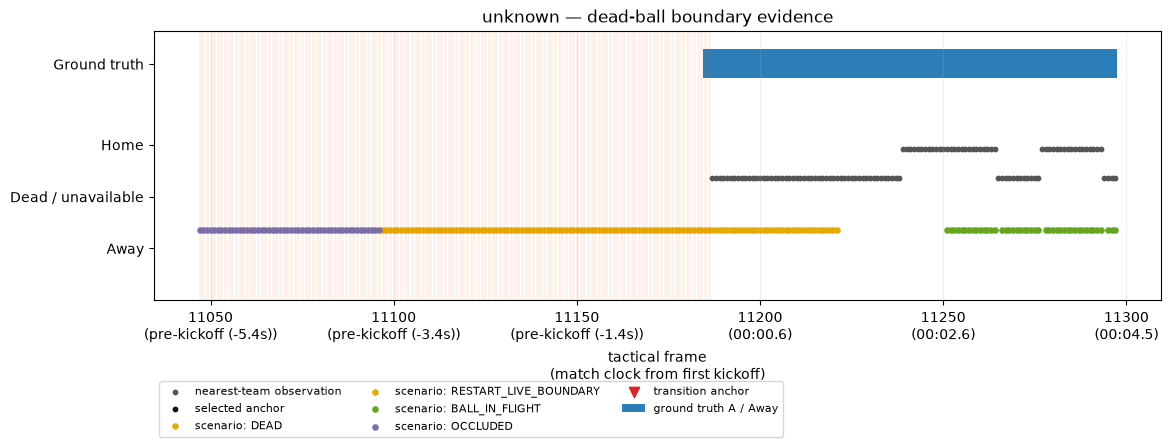

In [3]:
if not audit.empty:
    for restart_type, group in audit.groupby('type', sort=True):
        event = group.iloc[0]
        left = max(int(features['frame'].min()), int(event['start_frame']) - 50)
        right = min(int(features['frame'].max()), int(event['end_frame']) + 75)
        fig, ax = plot_timeline_window(features, left, right, ground_truth=insight_gt)
        ax.set_title(f'{restart_type} — dead-ball boundary evidence')
        plt.show()


## Pipeline conclusion

- Smart Tagging identifies where to inspect.
- Physical restart activation identifies when live play begins.
- Kick distance, speed, acceleration, direction, density, and receiver control determine confidence.
- The decoder receives the same evidence for every scenario and decides how conservatively to transition from D to H/A.